# 02 · Generalización cruzada (LODO binario multi-semilla): efecto del aumento de datos (`Base` vs. `Con aumento`)

**Pregunta:** Al dejar cada dataset completo fuera de entrenamiento (*Leave-One-Dataset-Out*, LODO) y repetir con **3 semillas independientes** (`42`, `123`, `777`), ¿cuánto cambia la detección binaria de glaucoma en `ConvNeXt-Tiny` al pasar de entrenamiento sin aumentos (`Base`) a `AumentoEscalaFotometrico` + volteos (`Con aumento`)?

**Rigor metodológico:**
- **Independiente de `04`:** esquema puramente binario (`2.056` imágenes auditadas sin fuga de datos).
- **Multi-semilla (`4 folds × 2 brazos × 3 semillas = 24 modelos`):** separa el efecto real del aumento de la variabilidad estocástica del entrenamiento.
- **Análisis de sensibilidad a $\tau$ + métricas libres de umbral (`AUROC`, `AP`) + IC 95 % bootstrap:** distingue la capacidad intrínseca de ordenamiento del efecto de trasladar el punto de corte (`Espec. val ≥ 0.95`, `Youden`, y `τ = 0.50`).

## 1. Configuración y particiones *Leave-One-Dataset-Out* (LODO)

Se precargan las `2.056` imágenes limpias una sola vez en memoria (`max_lado=448`) para garantizar idéntico preprocesamiento y acelerar las 24 corridas.

In [1]:
%matplotlib inline
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split
from torchvision import transforms as T

_root = Path.cwd().resolve()
if not (_root / "utilidades/utilidades.py").is_file() and (_root.parent / "utilidades/utilidades.py").is_file():
    _root = _root.parent
sys.path.insert(0, str(_root / "utilidades"))
sys.path.insert(0, str(_root / "03_experimento_caracteristicas_retinografias/scripts"))

import utilidades as u
from metricas_retinografias import retinal_mask, thumbnail

ROOT = u.obtener_raiz()
SALIDAS = ROOT / "05_experimento_data_augmentation/resultados"
SALIDAS.mkdir(parents=True, exist_ok=True)
MODELOS = ROOT / "modelos"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS = 20
BATCH_SIZE = 32
REENTRENAR = False
SEMILLAS = [42, 123, 777]
COHORTES_LODO = ["Moondream Staged", "ACRIMA", "RIM-ONE DL", "EyePACS REAL"]

def slugify(nombre: str) -> str:
    return re.sub(r"[^a-z0-9]+", "_", nombre.lower()).strip("_")

u.fijar_semilla(u.SEED)
df_datos, _ = u.cargar_dataset(ROOT)
df_datos = df_datos[df_datos["coleccion"].isin(COHORTES_LODO)].reset_index(drop=True)
cache_imgs = u.precargar_imagenes(df_datos["id"].tolist(), ROOT, max_lado=448)

folds = {}
resumen_folds = []
for held_out in COHORTES_LODO:
    test_df = df_datos[df_datos["coleccion"] == held_out].reset_index(drop=True)
    pool_df = df_datos[df_datos["coleccion"] != held_out].reset_index(drop=True)
    estrato = pool_df["coleccion"] + "_" + pool_df["y2"].astype(int).astype(str)
    train_df, val_df = train_test_split(
        pool_df, test_size=0.15, stratify=estrato, random_state=u.SEED
    )
    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    folds[held_out] = {"train": train_df, "val": val_df, "test": test_df}
    resumen_folds.append({
        "cohorte_fuera": held_out,
        "train_n": len(train_df), "train_pos_%": round(100 * train_df["y2"].mean(), 1),
        "val_n": len(val_df), "val_pos_%": round(100 * val_df["y2"].mean(), 1),
        "test_ciego_n": len(test_df), "test_pos_%": round(100 * test_df["y2"].mean(), 1),
    })

df_folds = pd.DataFrame(resumen_folds)
df_folds.to_csv(SALIDAS / "02_resumen_folds_lodo.csv", index=False)
print(f"Dispositivo: {DEVICE} | Imágenes en caché RAM: {len(cache_imgs)} | Semillas: {SEMILLAS}")
display(df_folds)

Dispositivo: cuda | Imágenes en caché RAM: 2056 | Semillas: [42, 123, 777]


,cohorte_fuera,train_n,train_pos_%,val_n,val_pos_%,test_ciego_n,test_pos_%
0,Moondream Staged,1147,48.6,203,48.8,706,48.2
1,ACRIMA,1150,44.5,203,44.3,703,56.2
2,RIM-ONE DL,1367,51.9,242,52.1,447,36.2
3,EyePACS REAL,1577,48.3,279,48.4,200,50.0


## 2. Comprobación visual y fotométrica (`Base` vs. `Con aumento`)

`Con aumento` se aplica **solo en entrenamiento** (`zoom-out` con fondo sintético circular, `zoom-in` aleatorio, volteos y ajuste de gamma/verde). Validación y test externo usan siempre `Base` (redimensionado simple a $224\times 224$).

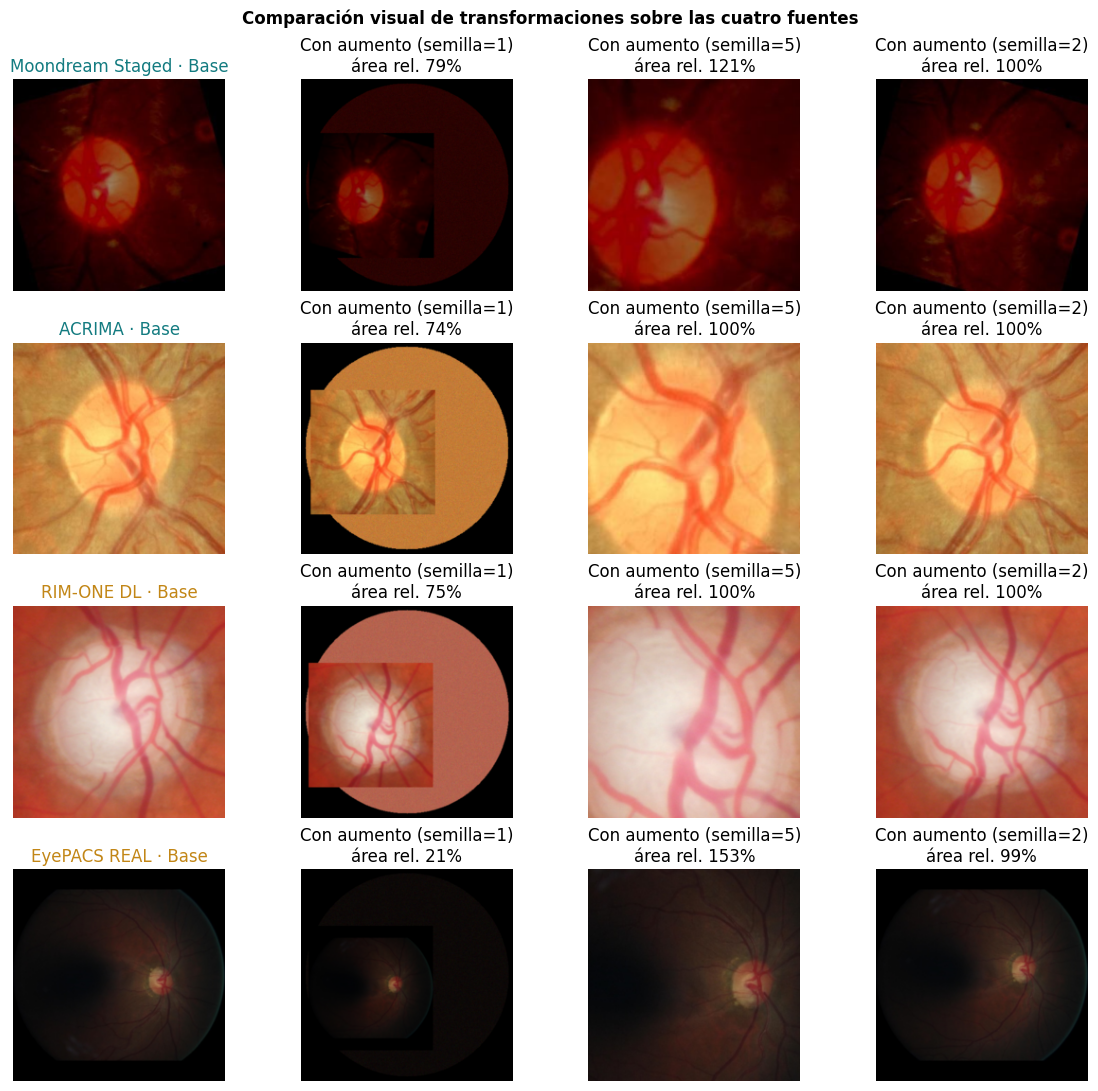

R       G      B  casi_negro_pct
cohorte          brazo                                             
ACRIMA           Base         189.02  100.42  22.76            0.00
                 Con aumento  162.04   86.76  18.87            0.05
EyePACS REAL     Base          82.14   56.63  34.35           21.36
                 Con aumento   78.14   45.32  28.53           27.84
Moondream Staged Base         164.27  107.15  46.35            0.00
                 Con aumento  142.40   93.00  41.71            9.49
RIM-ONE DL       Base         158.54   67.21  33.64            0.00
                 Con aumento  129.41   60.00  26.17            0.00

In [2]:
tf_base = T.Resize((224, 224))
tf_aumento = T.Compose([
    u.AumentoEscalaFotometrico(output_size=(224, 224)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
])

def porc_negro_y_rgb(img_pil):
    arr = np.asarray(img_pil)
    r, g, b = arr.mean(axis=(0, 1))
    negro = 100.0 * (arr.max(axis=2) <= 10).mean()
    return {"R": r, "G": g, "B": b, "casi_negro_pct": negro}

def retencion_campo(img_orig, img_aug):
    m0, cat0 = retinal_mask(thumbnail(np.asarray(img_orig)))
    m1, cat1 = retinal_mask(thumbnail(np.asarray(img_aug)))
    if m0 is None or m1 is None or cat0 == "sin_componente_visible" or cat1 == "sin_componente_visible":
        return np.nan
    return 100.0 * m1.mean() / max(m0.mean(), 1e-6)

ejemplos = df_datos.groupby("coleccion", sort=False).head(1)
fig, axes = plt.subplots(len(ejemplos), 4, figsize=(11.5, 2.7 * len(ejemplos)), layout="constrained")
for fila_ax, row in zip(axes, ejemplos.itertuples()):
    img = cache_imgs[row.id]
    fila_ax[0].imshow(tf_base(img))
    fila_ax[0].set_title(f"{row.coleccion} · Base", color=u.COLORES_CLASE[int(row.y2)])
    for ax, sem in zip(fila_ax[1:], (1, 5, 2)):
        u.fijar_semilla(sem)
        aug = tf_aumento(img)
        ax.imshow(aug)
        ret = retencion_campo(img, aug)
        ax.set_title(f"Con aumento (semilla={sem})" + (f"\nárea rel. {ret:.0f}%" if np.isfinite(ret) else ""))
    for ax in fila_ax:
        ax.axis("off")
fig.suptitle("Comparación visual de transformaciones sobre las cuatro fuentes", fontweight="bold")
plt.show()

muestra_df = df_datos.groupby(["coleccion", "y2"], sort=False).apply(
    lambda g: g.sample(n=min(50, len(g)), random_state=u.SEED), include_groups=False
).reset_index(level=[0, 1]).reset_index(drop=True)

senales = []
for i, row in enumerate(muestra_df.itertuples()):
    img = cache_imgs[row.id]
    u.fijar_semilla(u.SEED + i)
    for brazo, vista in (("Base", tf_base(img)), ("Con aumento", tf_aumento(img))):
        senales.append({"id": row.id, "cohorte": row.coleccion, "clase": row.clase, "y2": row.y2, "brazo": brazo, **porc_negro_y_rgb(vista)})

visual_df = pd.DataFrame(senales)
visual_df.to_csv(SALIDAS / "02_senales_visuales_pareadas.csv", index=False)
display(visual_df.groupby(["cohorte", "brazo"])[["R", "G", "B", "casi_negro_pct"]].median().round(2))

## 3. Entrenamiento LODO multi-semilla ($4\text{ folds} \times 2\text{ brazos} \times 3\text{ semillas}$)

Los `24` modelos binarios entrenan con protocolo idéntico (`AdamW`, warmup de 1 época + 20 épocas con `CosineAnnealingLR`). En cada *fold* y semilla se calibran **únicamente en validación** el corte conservador (`Espec. val ≥ 0.95`, grilla `[0.20, 0.99]`) y el punto **Youden**.

  [2 clases] Época 01/20 · train=0.416 · val=0.308 · score=0.824


  [2 clases] Época 05/20 · train=0.041 · val=0.203 · score=0.928


  [2 clases] Época 10/20 · train=0.005 · val=0.383 · score=0.915


  [2 clases] Época 15/20 · train=0.004 · val=0.415 · score=0.885


  [2 clases] Época 20/20 · train=0.001 · val=0.382 · score=0.915


  [2 clases] Época 01/20 · train=0.368 · val=0.230 · score=0.885


... (83 outputs left out)

  [2 clases] Época 10/20 · train=0.131 · val=0.209 · score=0.925


  [2 clases] Época 15/20 · train=0.081 · val=0.223 · score=0.911


  [2 clases] Época 20/20 · train=0.044 · val=0.229 · score=0.916


,cohorte_fuera,brazo,seed,mejor_epoca,tau_cons,espec_cons_val,tau_youd,espec_youd_val
0,Moondream Staged,Base,42,5,0.91,0.971,0.50,0.923
1,Moondream Staged,Base,123,5,0.63,0.952,0.50,0.942
2,Moondream Staged,Base,777,5,0.92,0.952,0.57,0.894
3,Moondream Staged,Con aumento,42,8,0.36,0.962,0.38,0.962
4,Moondream Staged,Con aumento,123,12,0.64,0.952,0.50,0.923
5,Moondream Staged,Con aumento,777,5,0.75,0.952,0.56,0.913
6,ACRIMA,Base,42,10,0.99,0.947,0.50,0.814
7,ACRIMA,Base,123,3,0.98,0.965,0.70,0.841
8,ACRIMA,Base,777,3,0.97,0.973,0.50,0.858
9,ACRIMA,Con aumento,42,3,0.90,0.956,0.69,0.814


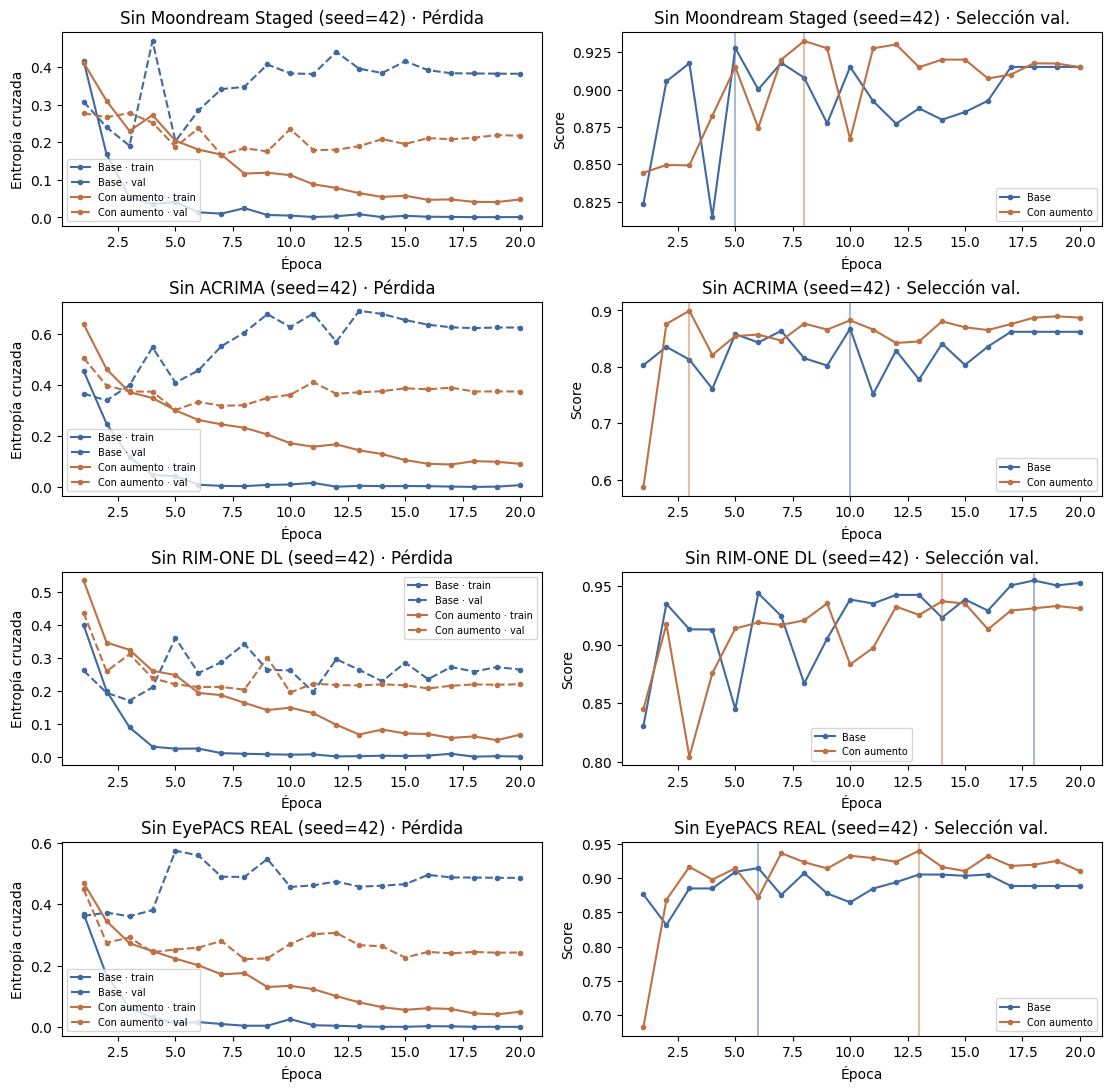

In [3]:
to_tensor = T.Compose([T.ToTensor(), T.Normalize(u.MEAN, u.STD)])
tf_eval = T.Compose([tf_base, to_tensor])
sufijos = {"Base": "base", "Con aumento": "aumento"}
recetas = {"Base": tf_eval, "Con aumento": T.Compose([tf_aumento, to_tensor])}

corridas = {}
for held_out in COHORTES_LODO:
    slug = slugify(held_out)
    tr_df = folds[held_out]["train"]
    va_df = folds[held_out]["val"]
    te_df = folds[held_out]["test"]
    te_loader = u.crear_loader(te_df, ROOT, 2, tf_eval, batch_size=BATCH_SIZE, device=DEVICE, cache_imgs=cache_imgs)

    for brazo, tf_tr in recetas.items():
        for seed in SEMILLAS:
            suf_seed = "" if seed == 42 else f"_s{seed}"
            ruta_pth = MODELOS / f"convnext_tiny_lodo_sin_{slug}_{sufijos[brazo]}{suf_seed}.pth"
            res = u.entrenar_o_cargar(
                tr_df, va_df, ROOT, 2, tf_tr, tf_eval,
                ruta_modelo=ruta_pth, epochs=EPOCHS, batch_size=BATCH_SIZE,
                device=DEVICE, reentrenar=REENTRENAR, seed=seed, cache_imgs=cache_imgs,
            )
            y_val = va_df["y2"].to_numpy(int)
            tau_cons, espec_cons = u.calibrar_umbral(y_val, res["val_prob"], 2)
            tau_youd, espec_youd = u.calibrar_youden(y_val, res["val_prob"])
            _, test_prob = u.predecir(res["model"], te_loader, DEVICE, calcular_loss=False)

            corridas[held_out, brazo, seed] = {
                "hist": res["hist"], "epoca": res["epoca"],
                "tau_cons": tau_cons, "espec_cons": espec_cons,
                "tau_youd": tau_youd, "espec_youd": espec_youd,
                "test_prob": test_prob,
            }
            del res["model"]
            if DEVICE == "cuda":
                torch.cuda.empty_cache()

tabla_cal = [
    {"cohorte_fuera": coh, "brazo": br, "seed": sd, "mejor_epoca": r["epoca"],
     "tau_cons": r["tau_cons"], "espec_cons_val": r["espec_cons"],
     "tau_youd": r["tau_youd"], "espec_youd_val": r["espec_youd"]}
    for (coh, br, sd), r in corridas.items()
]
display(pd.DataFrame(tabla_cal).round(3))

# Curvas de aprendizaje (semilla 42)
fig, axes = plt.subplots(len(COHORTES_LODO), 2, figsize=(11, 2.7 * len(COHORTES_LODO)), layout="constrained")
for idx, coh in enumerate(COHORTES_LODO):
    for color, br in zip(u.COLORES_FUENTE, ("Base", "Con aumento")):
        r = corridas[coh, br, 42]
        h = r["hist"]
        axes[idx, 0].plot(h["epoca"], h["train"], color=color, marker=".", label=f"{br} · train")
        axes[idx, 0].plot(h["epoca"], h["val"], "--", color=color, marker=".", label=f"{br} · val")
        axes[idx, 1].plot(h["epoca"], h["score"], color=color, marker=".", label=br)
        axes[idx, 1].axvline(r["epoca"], color=color, alpha=0.45)
    axes[idx, 0].set(title=f"Sin {coh} (seed=42) · Pérdida", xlabel="Época", ylabel="Entropía cruzada")
    axes[idx, 1].set(title=f"Sin {coh} (seed=42) · Selección val.", xlabel="Época", ylabel="Score")
    axes[idx, 0].legend(fontsize=7)
    axes[idx, 1].legend(fontsize=7)
plt.show()

## 4. Evaluación LODO multi-semilla, sensibilidad al umbral $\tau$ e IC 95 % bootstrap

Reportamos:
1. **Estabilidad entre las 3 semillas (`media ± DE`)** bajo la regla principal (`Espec. val ≥ 0.95`), más el contraste pareado del **ensamble promedio entre semillas** (curvas ROC/PR, matrices e **IC 95 % bootstrap incluyendo `AUROC`**).
2. **Sensibilidad al punto de corte:** comparación lado a lado de `Espec. val ≥ 0.95`, `Youden (val)` y `Estándar (τ = 0.50)`.

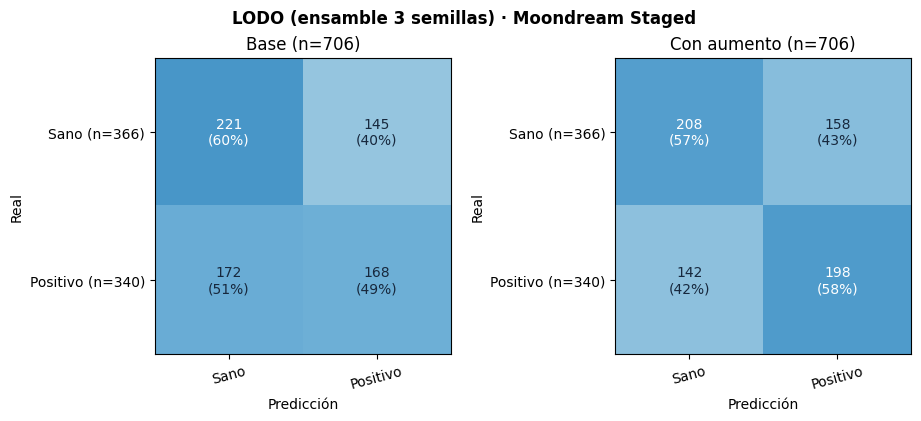

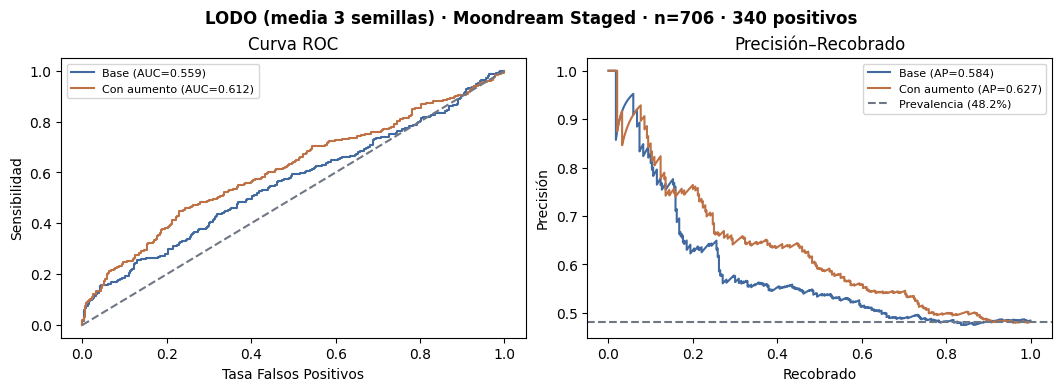

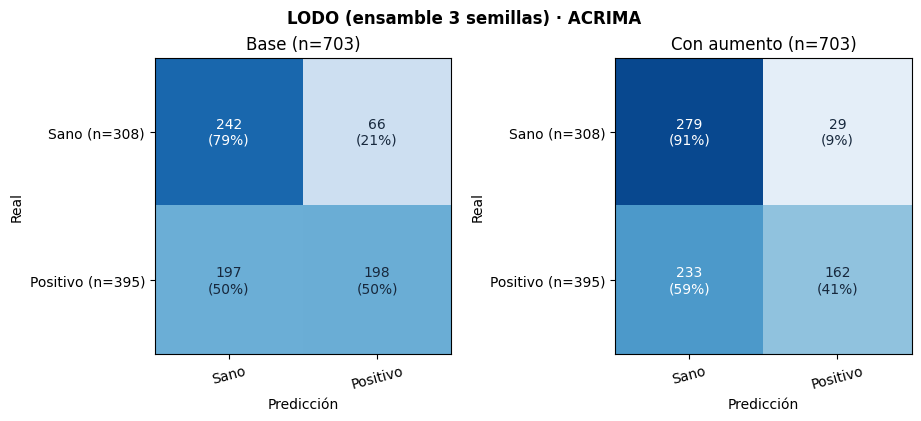

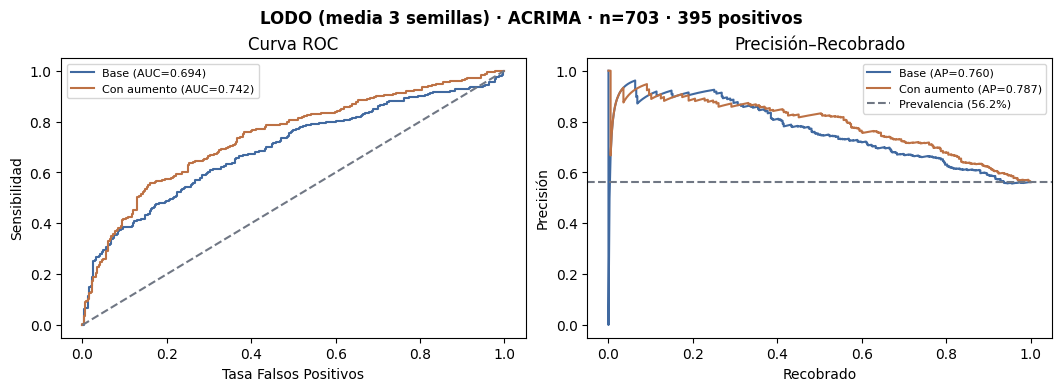

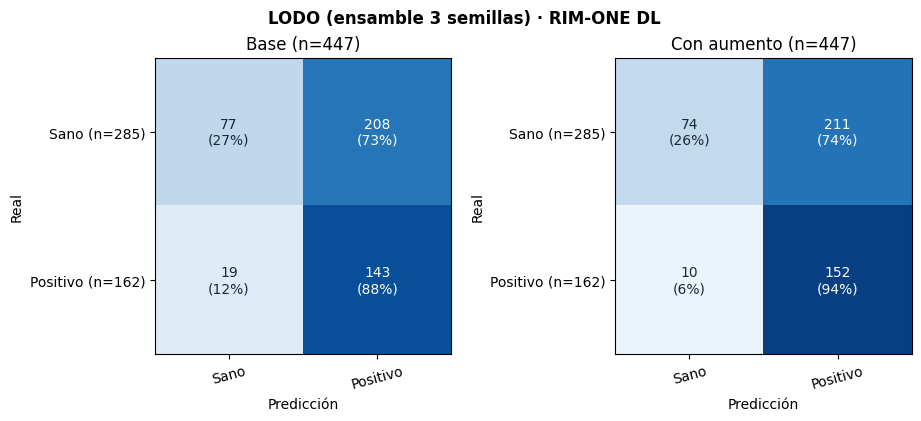

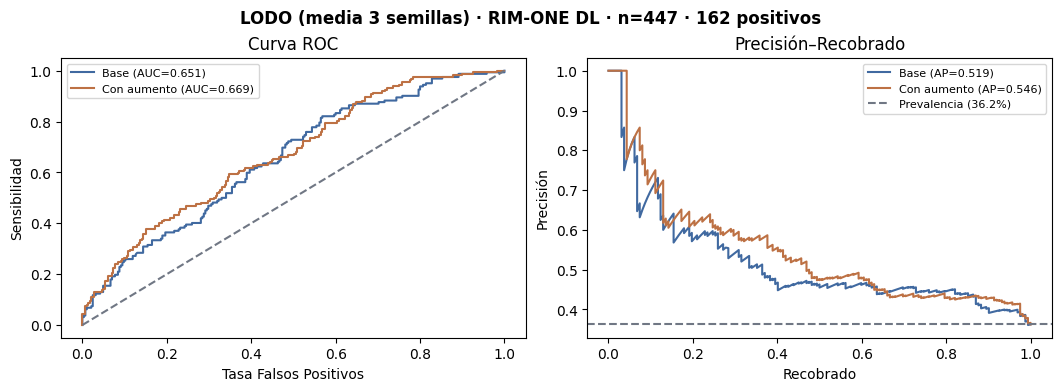

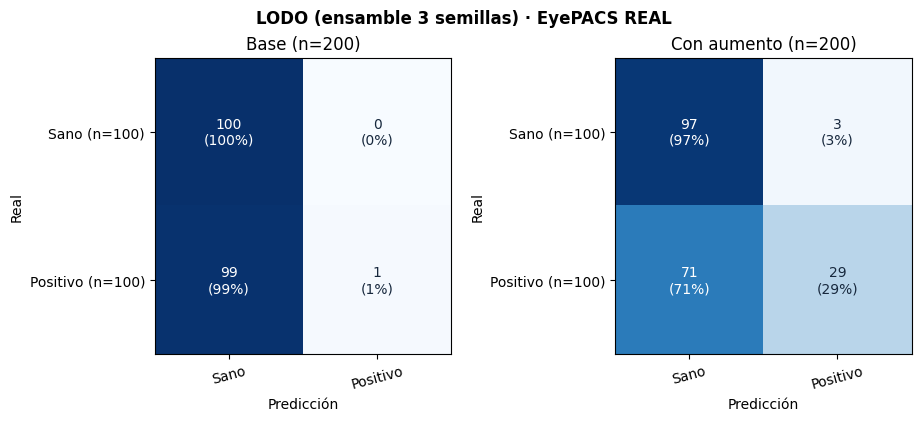

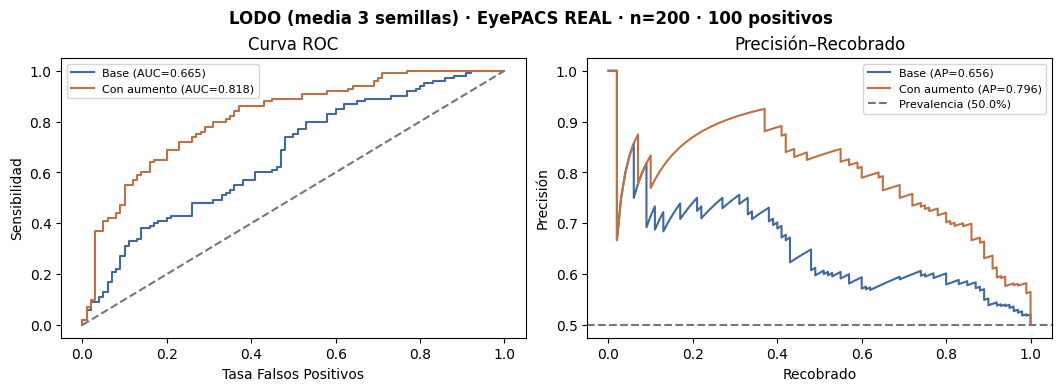

Resumen LODO multi-semilla (media y DE sobre 3 semillas, regla Espec. val ≥ 0.95):


F1 macro        exactitud        sensibilidad  \
                                 mean    std      mean    std         mean   
cohorte_fuera    brazo                                                       
Moondream Staged Base           0.519  0.031     0.525  0.035        0.514   
                 Con aumento    0.580  0.011     0.582  0.012        0.604   
ACRIMA           Base           0.625  0.024     0.625  0.024        0.527   
                 Con aumento    0.628  0.084     0.635  0.075        0.475   
RIM-ONE DL       Base           0.484  0.054     0.497  0.046        0.889   
                 Con aumento    0.485  0.044     0.501  0.035        0.928   
EyePACS REAL     Base           0.343  0.001     0.502  0.003        0.010   
                 Con aumento    0.618  0.039     0.653  0.028        0.353   

                                    especificidad           TFP           TFN  \
                                std          mean    std   mean    std   mean   
cohorte_fuera    brazo                                                          
Moondream Staged Base         0.141         0.536  0.144  0.464  0.144  0.486   
                 Con aumento  0.080         0.561  0.092  0.439  0.092  0.396   
ACRIMA           Base         0.035         0.751  0.013  0.249  0.013  0.473   
                 Con aumento  0.150         0.841  0.076  0.159  0.076  0.525   
RIM-ONE DL       Base         0.006         0.274  0.075  0.726  0.075  0.111   
                 Con aumento  0.025         0.258  0.064  0.742  0.064  0.072   
EyePACS REAL     Base         0.000         0.993  0.006  0.007  0.006  0.990   
                 Con aumento  0.060         0.953  0.006  0.047  0.006  0.647   

                                     AUROC            AP           tau         
                                std   mean    std   mean    std   mean    std  
cohorte_fuera    brazo                                                         
Moondream Staged Base         0.141  0.556  0.054  0.571  0.060  0.820  0.165  
                 Con aumento  0.080  0.605  0.016  0.619  0.009  0.583  0.201  
ACRIMA           Base         0.035  0.686  0.026  0.755  0.021  0.980  0.010  
                 Con aumento  0.150  0.730  0.055  0.778  0.068  0.937  0.032  
RIM-ONE DL       Base         0.006  0.671  0.039  0.560  0.050  0.860  0.106  
                 Con aumento  0.025  0.676  0.043  0.564  0.063  0.817  0.040  
EyePACS REAL     Base         0.000  0.655  0.018  0.644  0.030  0.967  0.025  
                 Con aumento  0.060  0.809  0.014  0.786  0.030  0.937  0.031

Sensibilidad al punto de corte τ (media sobre 3 semillas):


tau  F1 macro  \
cohorte_fuera    regla               brazo                          
Moondream Staged Espec. val ≥ 0.95   Base         0.820     0.519   
                 Youden (val)        Base         0.523     0.507   
                 Estándar (τ = 0.50) Base         0.500     0.505   
                 Espec. val ≥ 0.95   Con aumento  0.583     0.580   
                 Youden (val)        Con aumento  0.480     0.570   
                 Estándar (τ = 0.50) Con aumento  0.500     0.568   
ACRIMA           Espec. val ≥ 0.95   Base         0.980     0.625   
                 Youden (val)        Base         0.567     0.606   
                 Estándar (τ = 0.50) Base         0.500     0.592   
                 Espec. val ≥ 0.95   Con aumento  0.937     0.628   
                 Youden (val)        Con aumento  0.713     0.664   
                 Estándar (τ = 0.50) Con aumento  0.500     0.661   
RIM-ONE DL       Espec. val ≥ 0.95   Base         0.860     0.484   
                 Youden (val)        Base         0.783     0.452   
                 Estándar (τ = 0.50) Base         0.500     0.397   
                 Espec. val ≥ 0.95   Con aumento  0.817     0.485   
                 Youden (val)        Con aumento  0.713     0.462   
                 Estándar (τ = 0.50) Con aumento  0.500     0.409   
EyePACS REAL     Espec. val ≥ 0.95   Base         0.967     0.343   
                 Youden (val)        Base         0.587     0.537   
                 Estándar (τ = 0.50) Base         0.500     0.572   
                 Espec. val ≥ 0.95   Con aumento  0.937     0.618   
                 Youden (val)        Con aumento  0.623     0.715   
                 Estándar (τ = 0.50) Con aumento  0.500     0.721   

                                                  sensibilidad  especificidad  \
cohorte_fuera    regla               brazo                                      
Moondream Staged Espec. val ≥ 0.95   Base                0.514          0.536   
                 Youden (val)        Base                0.658          0.388   
                 Estándar (τ = 0.50) Base                0.662          0.381   
                 Espec. val ≥ 0.95   Con aumento         0.604          0.561   
                 Youden (val)        Con aumento         0.645          0.505   
                 Estándar (τ = 0.50) Con aumento         0.634          0.511   
ACRIMA           Espec. val ≥ 0.95   Base                0.527          0.751   
                 Youden (val)        Base                0.766          0.451   
                 Estándar (τ = 0.50) Base                0.783          0.417   
                 Espec. val ≥ 0.95   Con aumento         0.475          0.841   
                 Youden (val)        Con aumento         0.658          0.676   
                 Estándar (τ = 0.50) Con aumento         0.760          0.564   
RIM-ONE DL       Espec. val ≥ 0.95   Base                0.889          0.274   
                 Youden (val)        Base                0.912          0.222   
                 Estándar (τ = 0.50) Base                0.957          0.142   
                 Espec. val ≥ 0.95   Con aumento         0.928          0.258   
                 Youden (val)        Con aumento         0.955          0.219   
                 Estándar (τ = 0.50) Con aumento         0.975          0.149   
EyePACS REAL     Espec. val ≥ 0.95   Base                0.010          0.993   
                 Youden (val)        Base                0.333          0.827   
                 Estándar (τ = 0.50) Base                0.423          0.753   
                 Espec. val ≥ 0.95   Con aumento         0.353          0.953   
                 Youden (val)        Con aumento         0.640          0.797   
                 Estándar (τ = 0.50) Con aumento         0.707          0.737   

                                                    TFN    TFP  AUROC  
cohorte_fuera    regla               brazo                             
Moondr

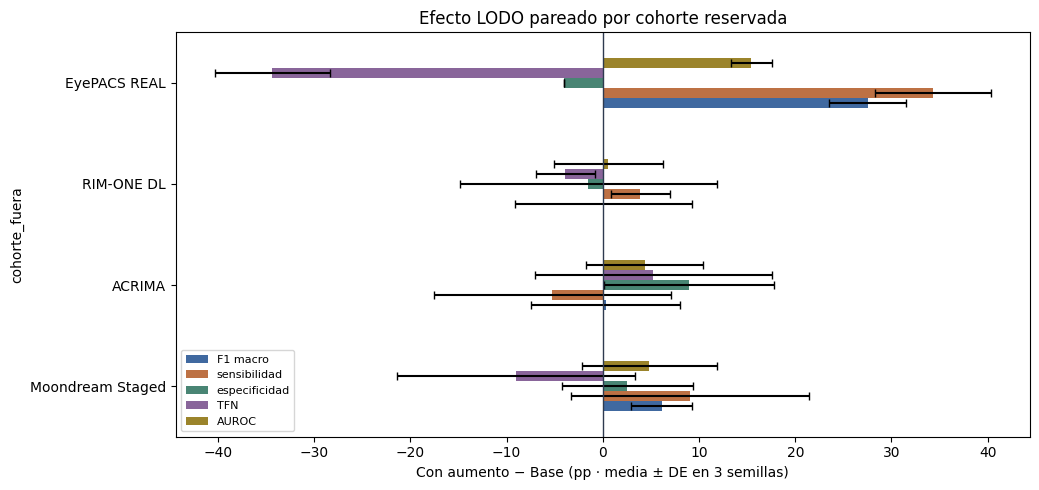

Intervalos de confianza 95% bootstrap para Con aumento − Base (ensamble 3 semillas, incluye AUROC):


,medida,delta,ic95_inf,ic95_sup,cohorte_fuera,n
0,F1 macro,0.027,0.003,0.050,Moondream Staged,706
1,sensibilidad,0.088,0.050,0.126,Moondream Staged,706
2,especificidad,-0.036,-0.066,-0.008,Moondream Staged,706
3,AUROC,0.052,0.035,0.071,Moondream Staged,706
4,F1 macro,-0.008,-0.038,0.021,ACRIMA,703
5,sensibilidad,-0.091,-0.132,-0.053,ACRIMA,703
6,especificidad,0.120,0.078,0.162,ACRIMA,703
7,AUROC,0.047,0.030,0.066,ACRIMA,703
8,F1 macro,0.009,-0.027,0.046,RIM-ONE DL,447
9,sensibilidad,0.056,0.025,0.093,RIM-ONE DL,447


LODO Moondream Staged: Δ F1=+6.1±3.2 pp · Δ Sens=+9.0±12.4 pp · Δ AUROC=+4.8±7.0 pp
LODO ACRIMA: Δ F1=+0.3±7.8 pp · Δ Sens=-5.2±12.3 pp · Δ AUROC=+4.4±6.1 pp
LODO RIM-ONE DL: Δ F1=+0.1±9.2 pp · Δ Sens=+3.9±3.0 pp · Δ AUROC=+0.6±5.7 pp
LODO EyePACS REAL: Δ F1=+27.5±4.0 pp · Δ Sens=+34.3±6.0 pp · Δ AUROC=+15.4±2.1 pp


In [4]:
reg_seed, reg_sens, intervalos, preds_out = [], [], [], []

for held_out in COHORTES_LODO:
    df_eval = folds[held_out]["test"]
    y = df_eval["y2"].to_numpy(int)
    panel_ens, scores_ens, preds_ens = {}, {}, {}

    for brazo in ("Base", "Con aumento"):
        probs_sem = [u.p_positivo(corridas[held_out, brazo, sd]["test_prob"]) for sd in SEMILLAS]
        taus_cons = [corridas[held_out, brazo, sd]["tau_cons"] for sd in SEMILLAS]
        taus_youd = [corridas[held_out, brazo, sd]["tau_youd"] for sd in SEMILLAS]

        for sd, sc, tc, ty in zip(SEMILLAS, probs_sem, taus_cons, taus_youd):
            r = corridas[held_out, brazo, sd]
            st_c, _ = u.calcular_metricas(y, (sc >= tc).astype(int), 2, score_binario=sc)
            reg_seed.append({"cohorte_fuera": held_out, "brazo": brazo, "seed": sd, "tau": tc, "epoca": r["epoca"], **st_c})
            for regla, t_val in [("Espec. val ≥ 0.95", tc), ("Youden (val)", ty), ("Estándar (τ = 0.50)", 0.50)]:
                m_r, _ = u.calcular_metricas(y, (sc >= t_val).astype(int), 2, score_binario=sc)
                reg_sens.append({"cohorte_fuera": held_out, "brazo": brazo, "seed": sd, "regla": regla, "tau": t_val, **m_r})

        # Ensamble promedio de probabilidades entre las 3 semillas + umbral medio
        sc_ens = np.mean(probs_sem, axis=0)
        tau_ens = float(np.mean(taus_cons))
        pred_e = (sc_ens >= tau_ens).astype(int)
        _, cm_e = u.calcular_metricas(y, pred_e, 2, score_binario=sc_ens)
        panel_ens[brazo], scores_ens[brazo], preds_ens[brazo] = cm_e, sc_ens, pred_e
        preds_out.append(df_eval[["id", "clase", "grupo", "y2"]].assign(
            cohorte_fuera=held_out, brazo=brazo, tau_media=tau_ens, prob_media=sc_ens, pred_media=pred_e
        ))

    u.graficar_matrices(panel_ens, u.CLASES_2, f"LODO (ensamble 3 semillas) · {held_out}")
    u.graficar_curvas_binarias(y, scores_ens, f"LODO (media 3 semillas) · {held_out}")
    ic = u.bootstrap_diferencia(
        y, preds_ens["Base"], preds_ens["Con aumento"], 2,
        score_antes=scores_ens["Base"], score_despues=scores_ens["Con aumento"],
    )
    if len(ic):
        intervalos.append(ic.assign(cohorte_fuera=held_out, n=len(df_eval)))

df_seed = pd.DataFrame(reg_seed)
df_sens = pd.DataFrame(reg_sens)
cols_met = ["F1 macro", "exactitud", "sensibilidad", "especificidad", "TFP", "TFN", "AUROC", "AP"]
df_agg = df_seed.groupby(["cohorte_fuera", "brazo"], sort=False)[cols_met + ["tau"]].agg(["mean", "std"]).round(4)

df_seed.to_csv(SALIDAS / "02_metricas_lodo_por_semilla.csv", index=False)
df_sens.to_csv(SALIDAS / "02_sensibilidad_umbral_lodo.csv", index=False)
df_agg.to_csv(SALIDAS / "02_metricas_lodo.csv")
pd.concat(preds_out, ignore_index=True).to_csv(SALIDAS / "02_predicciones_lodo.csv", index=False)

print("Resumen LODO multi-semilla (media y DE sobre 3 semillas, regla Espec. val ≥ 0.95):")
display(df_agg.round(3))

print("Sensibilidad al punto de corte τ (media sobre 3 semillas):")
display(df_sens.groupby(["cohorte_fuera", "regla", "brazo"], sort=False)[["tau", "F1 macro", "sensibilidad", "especificidad", "TFN", "TFP", "AUROC"]].mean().round(3))

# Gráfica delta media ± DE entre semillas
piv_m = df_seed.pivot_table(index=["cohorte_fuera", "seed"], columns="brazo", values=["F1 macro", "sensibilidad", "especificidad", "TFN", "AUROC"])
deltas_s = pd.DataFrame({m: 100 * (piv_m[(m, "Con aumento")] - piv_m[(m, "Base")]) for m in ["F1 macro", "sensibilidad", "especificidad", "TFN", "AUROC"]})
d_mean = deltas_s.groupby("cohorte_fuera", sort=False).mean().reindex(COHORTES_LODO)
d_std = deltas_s.groupby("cohorte_fuera", sort=False).std().reindex(COHORTES_LODO)

ax = d_mean.plot.barh(xerr=d_std, figsize=(10.5, 5.0), color=u.COLORES_FUENTE[:5], capsize=3)
ax.axvline(0, color="#2e3a4f", lw=1)
ax.set(xlabel="Con aumento − Base (pp · media ± DE en 3 semillas)", title="Efecto LODO pareado por cohorte reservada")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

if intervalos:
    print("Intervalos de confianza 95% bootstrap para Con aumento − Base (ensamble 3 semillas, incluye AUROC):")
    display(pd.concat(intervalos, ignore_index=True).round(3))

for coh in COHORTES_LODO:
    dm = d_mean.loc[coh]
    ds = d_std.loc[coh]
    print(f"LODO {coh}: Δ F1={dm['F1 macro']:+.1f}±{ds['F1 macro']:.1f} pp · "
          f"Δ Sens={dm.sensibilidad:+.1f}±{ds.sensibilidad:.1f} pp · "
          f"Δ AUROC={dm.AUROC:+.1f}±{ds.AUROC:.1f} pp")

## 5. Limitaciones

- Cada *fold* LODO mantiene proporciones naturales de tamaño entre las tres cohortes de entrenamiento (`1.350` a `1.856` imágenes) con entropía cruzada estándar.
- No se incluyen máscaras de disco/copa ni mapas de atribución espacial (`Grad-CAM`); las explicaciones geométricas provienen de las mediciones cuantitativas de encuadre y fotometría del experimento `03`.
- Este diseño evalúa exclusivamente clasificación binaria; la comparación trinario frente a binario corresponde de forma independiente al experimento `04`.